In [1]:
%load_ext autoreload
%autoreload 2
import sys
sys.path.append('..')
from src.data_loading import load_data, split_train_test_freq
from src.features import preparer, modalites_frequentes, regrouper, FORMULE_FREQUENCE
from src.graph import plot_freq_par_groupe, freq_par_groupe, plot_facteurs, plot_exposition_par_modalite
from src.metrics import comparer_tranches, seuil_aic_lr, seuil_bic_lr, seuil_test_lr, comparer_modeles_glm, lift_table, gini
from sklearn.metrics import mean_poisson_deviance
import numpy as np
import json
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy import stats

NB_OBS = 542410



freq, sev = load_data()
train, test = split_train_test_freq(freq, test_size=0.2, random_state=42)

for nom, table in [("train", train), ("test", test)]:
    print(f"Exposition totale de {nom} : ", table["Exposure"].sum().round(3))
    print(f"ClaimNb totale de {nom} : ", table["ClaimNb"].sum())
    print(f"Fréquence annualisée de {nom} : ", (table["ClaimNb"].sum() / table["Exposure"].sum()).round(5))

print("Proportion de l'exposition dans le test : ", (test["ClaimNb"].sum() / (test["ClaimNb"].sum()+train["ClaimNb"].sum())).round(4))

Exposition totale de train :  286776.503
ClaimNb totale de train :  28831
Fréquence annualisée de train :  0.10053
Exposition totale de test :  71583.603
ClaimNb totale de test :  7225
Fréquence annualisée de test :  0.10093
Proportion de l'exposition dans le test :  0.2004


`Exposition` : Même si le split porte sur le nombre de police et non sur l'exposition, le fait que par coïncidence 20% de l'exposition soit sur le jeu de test confirme qu'il n'y a pas de biais entre exposition et probabilité d'être tiré.

`Fréquences` : 0.10053 et 0.10093 cont 0.1005 sur le portefeuille complet. L'écart entre les deux est de 0.4%. Sachant que le test contient 7225 sinistres, l'incertitude relative (mesure suivant une statistique de poisson) sur sa fréquence est de `1/√7224 ≈ 1,2 %`. L'écart observé est environ 3 fois plus petit donc rien à signaler.

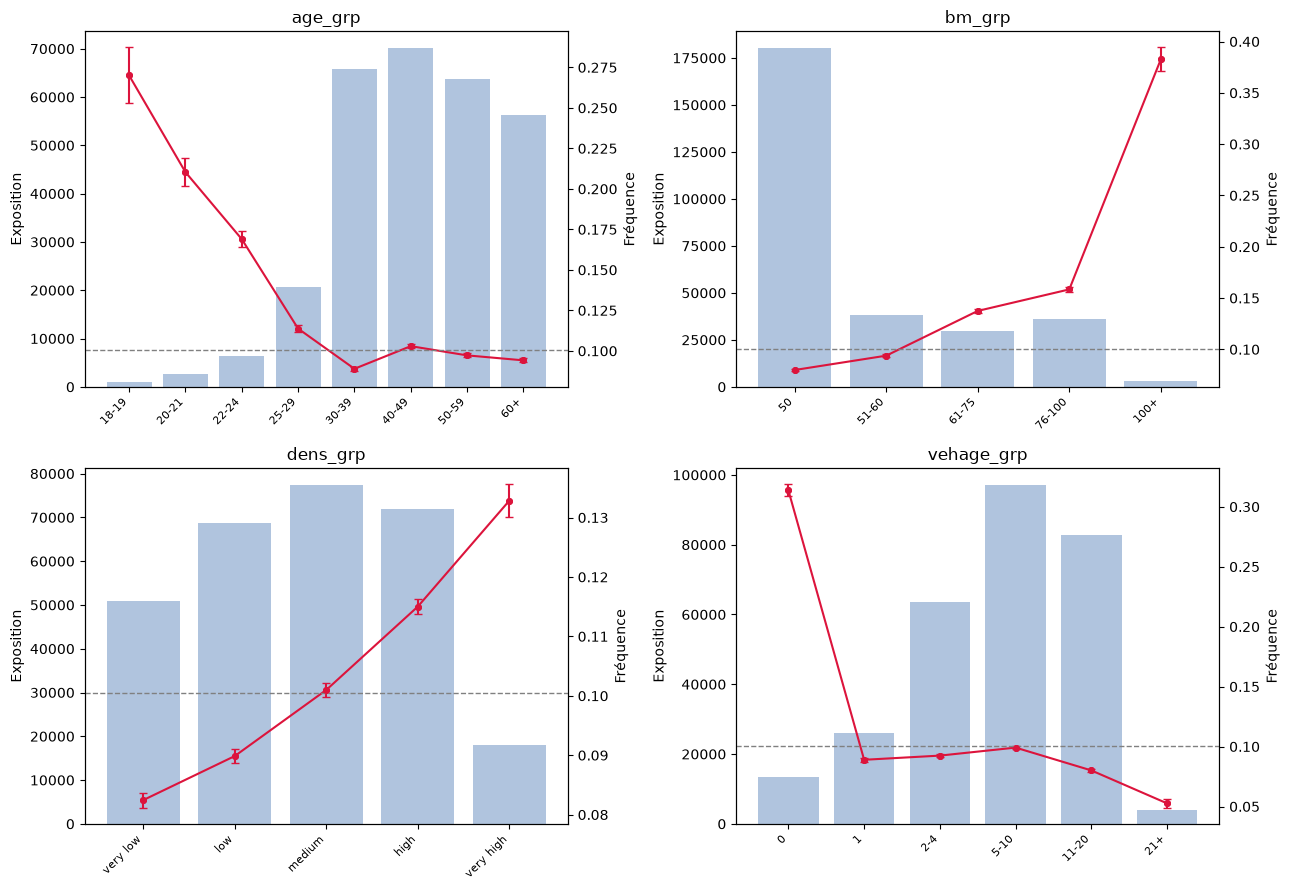

In [2]:
train_prep = preparer(train, decoupage="grossier")
test_prep  = preparer(test, decoupage="grossier")

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, col in zip(axes.flat, ["age_grp", "bm_grp", "dens_grp", "vehage_grp"]):
    plot_freq_par_groupe(train_prep, col, ax=ax, errorbar=True)
plt.tight_layout()


Pour les variables de catégorie, nous regroupons celles qui ont une exposition trop faible ( < 5000 ) car elles présenteraient une erreur relative trop importante sur la fréquence (pour 800 années-police -> environ 80 sinitres et une erreur relative de 11%).

In [3]:
modalites = {}

ETIQUETTE_AUTRE = {"VehPower": "12+", "Region": "Autres", "VehBrand": "Autres"}

for col in ["Region", "VehBrand", "VehPower"]:
    modalites[col] = modalites_frequentes(train_prep, col)
    train_prep = regrouper(train_prep, col, modalites[col], autre=ETIQUETTE_AUTRE[col])
    test_prep  = regrouper(test_prep,  col, modalites[col], autre=ETIQUETTE_AUTRE[col])


Nous allons regarder si certaines partie du découpages des variables `age_grp`, `bm_grp`, `dens_grp` et `vehage_grp` peuvent être fusionnées si elles ont un faible écart de fréquence et de petites erreurs relatives.

La statistique derrière cette fonction : l'écart type relatif du comptage vaut 1/√N (N = nombre de sinistres). Pour l'écart type de la fréquence, on divise par l'exposition qui est considérée comme une valeur connue et on obtient σ(f) = √N / exposition = f / √N.
Pour l'écart entre deux tranches, la variance d'une différence de deux variables aléatoires indépendantes est la somme des variances. Ainsi, le rapport |f₁ − f₂| / σ_écart compte l'écart en nombre d'écarts types ce qui permet de savoir réellement si l'écart observé est important.

In [4]:

for col in ["age_grp", "bm_grp", "dens_grp", "vehage_grp"]:
    print(f"\n === {col} === \n")
    print(comparer_tranches(train_prep, col))


 === age_grp === 

           paire     ecart  sigma_ecart   rapport
0  18-19 / 20-21  0.059678     0.019400  3.076198
1  20-21 / 22-24  0.041363     0.010237  4.040661
2  22-24 / 25-29  0.055220     0.005619  9.827525
3  25-29 / 30-39  0.024822     0.002620  9.473779
4  30-39 / 40-49  0.013979     0.001679  8.327129
5  40-49 / 50-59  0.005692     0.001730  3.291147
6    50-59 / 60+  0.003066     0.001788  1.714732

 === bm_grp === 

            paire     ecart  sigma_ecart    rapport
0      50 / 51-60  0.013968     0.001700   8.215515
1   51-60 / 61-75  0.043610     0.002664  16.369814
2  61-75 / 76-100  0.020974     0.003011   6.965382
3   76-100 / 100+  0.224172     0.011762  19.058303

 === dens_grp === 

              paire     ecart  sigma_ecart   rapport
0    very low / low  0.007413     0.001711  4.332397
1      low / medium  0.011127     0.001616  6.883772
2     medium / high  0.014026     0.001704  8.229313
3  high / very high  0.017828     0.003003  5.936061

 === vehage_gr

Pour `age_grp`, les fréquences de `60-69` (0.0934) et `70+` (0.0952) ne diffèrent que de 0.0012 pour un rapport de différence par rapport à l'écart-type de 0.68 . La distinction des deux catégorie n'est pas justifiée par les données observée, on peut donc les fusionner en `60+`.



Deux autres paires restent en zone grise et seront testé par AIC : 
- `age_grp` : `50-59` et `60+` (rapport 1.9)  
- `vehage_grp` : `1` et `2-4` (rapport 1.6)

In [5]:
X_train = train_prep
print(X_train.shape)
print(X_train.columns.tolist())

(542410, 17)
['IDpol', 'ClaimNb', 'Exposure', 'Area', 'VehPower', 'VehAge', 'DrivAge', 'BonusMalus', 'VehBrand', 'VehGas', 'Density', 'Region', 'age_grp', 'bm_grp', 'log_Density', 'dens_grp', 'vehage_grp']


In [6]:
y_train = train_prep["ClaimNb"]
offset_train = np.log(train_prep["Exposure"])

freq_formula = ("ClaimNb ~ C(age_grp, Treatment('30-39')) + C(bm_grp, Treatment('50'))"
        " + C(dens_grp, Treatment('medium')) + C(vehage_grp, Treatment('5-10'))"
        " + C(VehGas, Treatment('Regular')) + C(VehPower, Treatment('6'))"
        " + C(VehBrand, Treatment('B12')) + C(Region, Treatment('R24'))")


glm_freq = smf.glm(freq_formula, data=X_train, family=sm.families.Poisson(), offset=offset_train).fit()

print(glm_freq.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:                ClaimNb   No. Observations:               542410
Model:                            GLM   Df Residuals:                   542357
Model Family:                 Poisson   Df Model:                           52
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:            -1.1269e+05
Date:                Mon, 02 Nov 2026   Deviance:                   1.6993e+05
Time:                        09:30:27   Pearson chi2:                 1.25e+06
No. Iterations:                     7   Pseudo R-squ. (CS):            0.01705
Covariance Type:            nonrobust                                         
                                                    coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------------

In [7]:
mu = glm_freq.predict(X_train, offset=offset_train)
print("Somme des prédictions : ", mu.sum().round(1))
print("Somme des sinistres observés : ", y_train.sum())




Somme des prédictions :  28831.0
Somme des sinistres observés :  28831


### Spécification

Poisson à lien logarithmique, exposition en offset :

`log(E[ClaimNb]) = log(Exposure) + β′x`

L'offset entre avec un coefficient contraint à 1, de sorte que `exp(β′x)` s'interprète directement comme la fréquence annualisée.

53 paramètres estimés sur 542 410 polices.

Convergence de l'IRLS en 7 itérations.
Somme des prédictions égale à la somme des sinistres observés (propriété du lien canonique avec constante).
Aucune erreur standard aberrante : pas de colinéarité résiduelle après regroupement des modalités rares.

In [8]:
res = pd.DataFrame({"coef": glm_freq.params,"facteur": np.exp(glm_freq.params),"std_err": glm_freq.bse, "z": glm_freq.tvalues,}).round(4)
print(res)

                                                 coef  facteur  std_err  \
Intercept                                     -2.5432   0.0786   0.0327   
C(age_grp, Treatment('30-39'))[T.18-19]        0.7591   2.1364   0.0664   
C(age_grp, Treatment('30-39'))[T.20-21]        0.4121   1.5100   0.0460   
C(age_grp, Treatment('30-39'))[T.22-24]        0.1551   1.1677   0.0347   
C(age_grp, Treatment('30-39'))[T.25-29]       -0.0848   0.9187   0.0251   
C(age_grp, Treatment('30-39'))[T.40-49]        0.3537   1.4244   0.0183   
C(age_grp, Treatment('30-39'))[T.50-59]        0.3385   1.4029   0.0193   
C(age_grp, Treatment('30-39'))[T.60+]          0.3346   1.3973   0.0204   
C(bm_grp, Treatment('50'))[T.51-60]            0.2917   1.3388   0.0195   
C(bm_grp, Treatment('50'))[T.61-75]            0.6935   2.0007   0.0191   
C(bm_grp, Treatment('50'))[T.76-100]           0.8237   2.2788   0.0192   
C(bm_grp, Treatment('50'))[T.100+]             1.7050   5.5011   0.0337   
C(dens_grp, Treatment('me

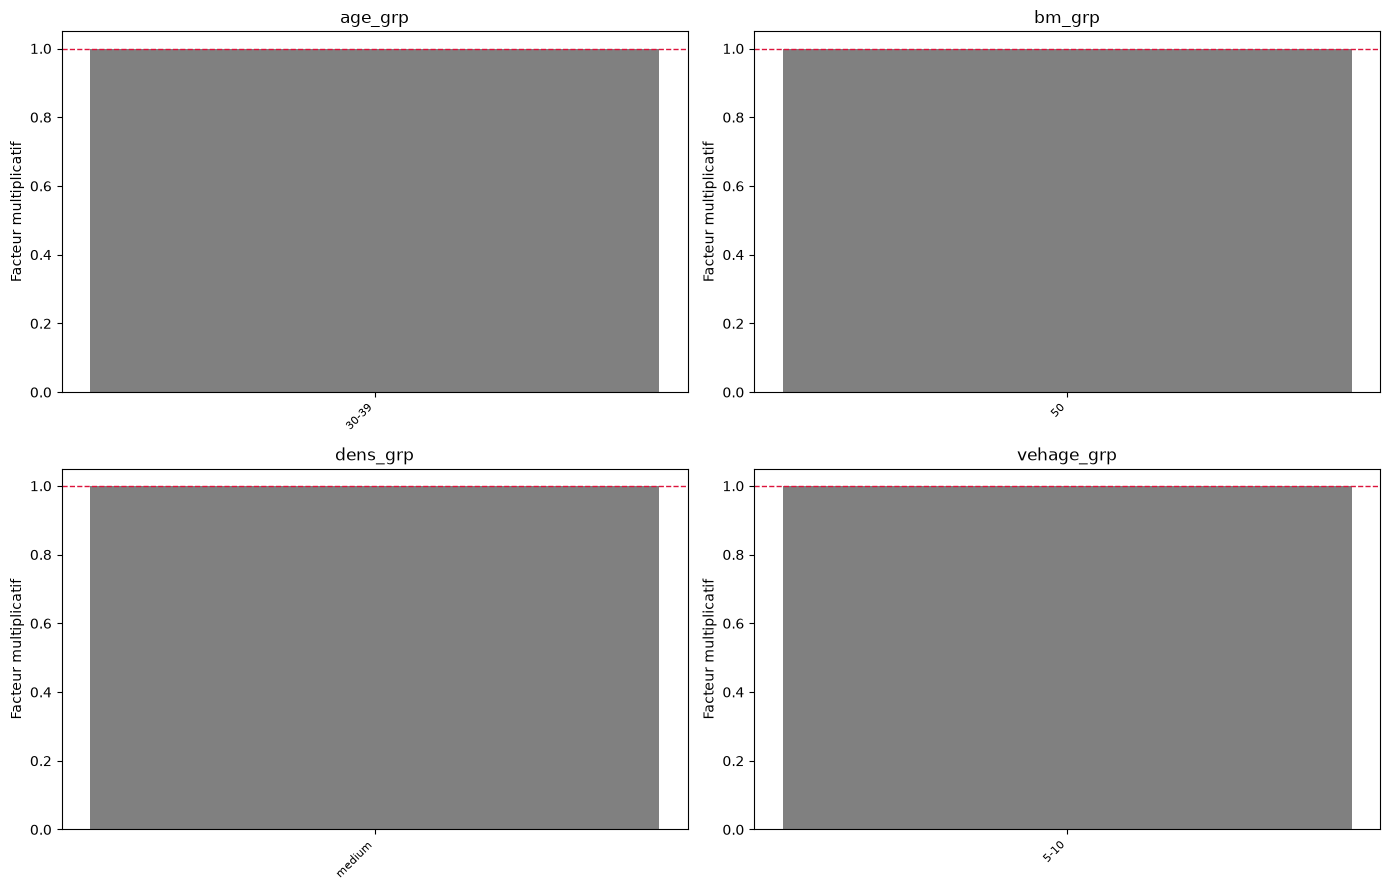

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
plot_facteurs(glm_freq, "age_grp", ref="30-39",ax=axes.flat[0])
plot_facteurs(glm_freq, "bm_grp", ref="50",ax=axes.flat[1])
plot_facteurs(glm_freq, "dens_grp", ref="medium",ax=axes.flat[2])
plot_facteurs(glm_freq, "vehage_grp", ref="5-10",ax=axes.flat[3])

plt.tight_layout()

### Grille tarifaire estimée

Profil de référence : conducteur de 30-39 ans, bonus 50, densité moyenne, véhicule essence de 5-10 ans, puissance 6, marque B12, région R24. Fréquence prédite : 0,0786.

#### L'effet de l'âge est grandement modifié par le contrôle.
| Tranche | Fréquence brute | Effet marginal |	Effet GLM |
|---|---|---|---|
|18-19|0,2700|×3,04|×2,14|
|20-21|	0,2104|	×2,37|	×1,51|
|22-24|0,1690|	×1,90|×1,17|
|25-29|	 0,1138|  ×1,28|	×0,92|
|30-39|	0,0889|	×1,00|	×1,00|
|40-49|0,1029|×1,16|	×1,42|
|50-59|0,0972|	×1,09|	×1,40|
|60+|	0,0940|	 ×1,06|	×1,40|

Observations : 

- Les jeunes sont attenués d'un tier. Le facteur 3.04 observé chez les `18-19` passe à 2.14 une fois les autres variables contrôlées.

- La tranche 25-29 change de signe. Supérieur de 28 % en brut, elle est inférieur de 8 % à profil comparable.

- Les 40+ sont amplifiés, de ×1,10 environ à ×1,40.

#### Autres variables :

- `Bonus-malus` : la variable dominante : ×1,34 (51-60), ×2,00 (61-75), ×2,28 (76-100), ×5,50 (100+). Strictement monotone, tous les coefficients au-delà de 14 σ montrent que cette variable est très significative dans la tarification.

- `Âge du véhicule` : le véhicule de moins d'un an ressort à ×3,12, contre ×3,17 en marginal : l'effet est pratiquement inchangé par le contrôle, donc indépendante aux autres variables. L'interprétation reste ouverte : déclaration systématique des dommages légers sur un véhicule neuf, relation contractuelle récente... Les données ne permettent pas de trancher.

- `Densité` : fortement atténuée : l'amplitude passe de 1 à 1,61 en marginal à 1 à 1,22 après contrôle.

- `Puissance, marque, région` — effets faibles et, pour la puissance, non monotones. Pl




|Question|	Raisonnement |
|---|---|
|Fusionner 40-49, 50-59 et 60+ en 40+|	Les coefficients des trois tranches au-delà de 40 ans valent 0,354, 0,339 et 0,335, pour des erreurs standards de l'ordre de 0,019. L'écart entre les extrêmes est de 0,019, soit 0,7 fois son propre écart-type : les trois tranches ne sont pas distinguables une fois les autres variables contrôlées.|
|Fusionner high et very high|	Écart de 0,012 pour un écart-type combiné de 0,032 soit 0,4 fois l'écart type.|
|Conserver VehPower ?|	Non monotone : ×0,76 en puissance 8, ×1,07 en 9, soit un saut de 41 % entre deux modalités contiguës — indéfendable dans une grille. Trois modalités non significatives. À tester en bloc par déviance.|
|Interaction age_grp × dens_grp|	Question ouverte depuis la phase 0 (ratios non constants de zone en zone).|



In [10]:
mask = (
    (train_prep["age_grp"] == "30-39") & (train_prep["bm_grp"] == "50")
    & (train_prep["dens_grp"] == "medium") & (train_prep["vehage_grp"] == "5-10")
    & (train_prep["VehGas"] == "Regular") & (train_prep["VehPower"] == "6")
    & (train_prep["VehBrand"] == "B12") & (train_prep["Region"] == "R24")
)
sous = train_prep[mask]
print(sous)
#print(len(sous), sous["Exposure"].sum(), sous["ClaimNb"].sum() / sous["Exposure"].sum())

Empty DataFrame
Columns: [IDpol, ClaimNb, Exposure, Area, VehPower, VehAge, DrivAge, BonusMalus, VehBrand, VehGas, Density, Region, age_grp, bm_grp, log_Density, dens_grp, vehage_grp]
Index: []


Je voulais vérifier que la fréquence annualisé d'un assuré présentant les caractéristiques de références était la même que celle prédite par le modèle mais aucun assuré ne les cummule toutes.

Cela n'invalide en rien les résultats, en effet certaines des caractéristiques de référence étaient en proportion faible dans le portefeuille, toutes cumulées, cela devient très rare.

Nous allons donc relâcher les contraintes faibles et garder les plus dominantes.

In [11]:
mask = (
    (train_prep["age_grp"] == "30-39")
    & (train_prep["bm_grp"] == "50")
    & (train_prep["vehage_grp"] == "5-10")
)
sous = train_prep[mask]
#print(sous)

print(len(sous), sous["Exposure"].sum().round(0), (sous["ClaimNb"].sum() / sous["Exposure"].sum()).round(4))

print(mu[mask].sum() / sous["Exposure"].sum())

14883 9470.0 0.0518
0.05793332001966062


In [12]:
print(f"Pearson χ²/df {(glm_freq.pearson_chi2 / glm_freq.df_resid).round(3)} (1.0 = perfect for Poisson)")

Pearson χ²/df 2.308 (1.0 = perfect for Poisson)


#### Réserve sur la dispersion

La loi de Poisson impose `Var(N) = E[N]`. Or cette contrainte est presque toujours brisée en assurance car les polices d'un même profil en apparance sont différentes sur des modalités non observées : kilométrage moyen, usage ...

Le rapport de Pearson `χ²/df = 2,30` évoque une surdispersion d'un facteur 2.30. Si la variance est 2.3 fois plus grande, alors les erreurs standards sont sous-estimées et les vrais sont `√2,3 ≈ 1,5` plus grandes. Les p-valeurs affichées sont donc trop optimistes, en particulier pour les modalités très significatives.

Une réserve est quand même émise sur la statistique de Pearson car elle divise par l'exposition qui peut être très petite. Ce chiffre peut donc être surestimé par quelques observations extrêmes.

La loi de Poisson suppose que la variance est égale à la moyenne. Les données suggèrent qu'elle est 2.3 fois plus grande, nous allons donc essayer avec une autre loi : la Negative-Binomial (Var = μ + αμ², avec α un paramètre de dispersion) qui estime directement l'excès de variance.

In [13]:
#on fait partir l'entrainement avec les parametre de la poisson pour que cela converge très vite vers la solution et gagner en temps de calcul.
start = np.append(glm_freq.params.to_numpy(), np.log(1.5))

glm_nb = smf.negativebinomial(freq_formula, data=X_train, offset=offset_train,loglike_method="nb2").fit(start_params=start , maxiter=200, disp=1)
print(glm_nb.summary())

Optimization terminated successfully.
         Current function value: 0.207339
         Iterations: 65
         Function evaluations: 68
         Gradient evaluations: 68
                     NegativeBinomial Regression Results                      
Dep. Variable:                ClaimNb   No. Observations:               542410
Model:               NegativeBinomial   Df Residuals:                   542357
Method:                           MLE   Df Model:                           52
Date:                Mon, 02 Nov 2026   Pseudo R-squ.:                 0.03813
Time:                        09:30:45   Log-Likelihood:            -1.1246e+05
converged:                       True   LL-Null:                   -1.1692e+05
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                                    coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------

In [14]:
mu = glm_nb.predict(X_train, offset=offset_train)
print("Somme des prédictions : ", mu.sum().round(1))
print("Somme des sinistres observés : ", y_train.sum())
print("Ecart en % : ", (mu.sum().round(4) - y_train.sum()) / y_train.sum() * 100)

# Calcule du facteur de recalage.

facteur = y_train.sum() / mu.sum()
mu_nb = mu * facteur
print("écart après recalage :", round(100 * (mu_nb.sum() - y_train.sum()) / y_train.sum(), 6))



Somme des prédictions :  29205.5
Somme des sinistres observés :  28831
Ecart en % :  1.2991200443966522
écart après recalage : 0.0


La binomiale négative surestime de 1,3 % (29 205 prédits), l'égalité des totaux n'étant pas garantie hors du cadre canonique. Un facteur de recalage multiplicatif de 0,9872, estimé sur le train, rétablit la calibration sans modifier les rapports entre segments.

In [15]:
comparaison = pd.DataFrame({
    'Poisson': np.exp(glm_freq.params),
    'Neg-Binomial': np.exp(glm_nb.params)
})

comparaison["Difference"] = comparaison["Poisson"] - comparaison["Neg-Binomial"]
comparaison['Diff_pct'] = (comparaison['Difference'] / comparaison['Poisson'] * 100)

print(comparaison.iloc[1:][['Poisson', 'Neg-Binomial', 'Diff_pct']].round(4).to_string())

                                               Poisson  Neg-Binomial  Diff_pct
C(Region, Treatment('R24'))[T.R11]              0.9068        0.9094   -0.2960
C(Region, Treatment('R24'))[T.R25]              0.9447        0.9442    0.0558
C(Region, Treatment('R24'))[T.R31]              0.8769        0.8784   -0.1698
C(Region, Treatment('R24'))[T.R41]              0.7796        0.7756    0.5157
C(Region, Treatment('R24'))[T.R52]              0.9409        0.9383    0.2776
C(Region, Treatment('R24'))[T.R53]              1.0319        1.0304    0.1466
C(Region, Treatment('R24'))[T.R54]              0.8902        0.8885    0.1867
C(Region, Treatment('R24'))[T.R72]              0.8476        0.8430    0.5496
C(Region, Treatment('R24'))[T.R73]              0.8267        0.8252    0.1777
C(Region, Treatment('R24'))[T.R82]              1.0088        1.0097   -0.0895
C(Region, Treatment('R24'))[T.R91]              0.8749        0.8752   -0.0325
C(Region, Treatment('R24'))[T.R93]              0.90

Écarts très faibles dans l'ensemble, sauf pour `vehage_grp_0` avec 5% puis `bm_grp_100+`, `age_grp_18-19`, `age_grp_20-21` et `bm_grp_76-100` au dessus de 1%.


`AIC = −2ℓ + 2k` 


`BIC = −2ℓ + log(n)·k ,  n = 542 410`


In [16]:
comp = pd.DataFrame({
    "log-vraisemblance": [glm_freq.llf, glm_nb.llf],
    "AIC": [glm_freq.aic, glm_nb.aic],
    "BIC": [glm_freq.bic_llf, glm_nb.bic],
    "paramètres": [53, 54],
}, index=["Poisson", "Binomiale négative"])
print(comp.round(1))

                    log-vraisemblance       AIC       BIC  paramètres
Poisson                     -112690.4  225486.8  226080.6          53
Binomiale négative          -112462.9  225033.7  225638.7          54


La binomiale négative ajuste mieux la dispersion mais perd la calibration automatique ; la Poisson est moins bien ajustée mais exactement calibrée. Pour un modèle destiné à produire un tarif, cette dernière propriété est loin d'être secondaire.

Modèle retenu : la binomiale négative. Elle est meilleur sur la vraissemblance, améliore l'AIC de 453 points et le BIC dans les mêmes proportions, pour un seul paramètre supplémentaire.

La différence ne porte pas sur le tarif : 45 des 53 coefficients diffèrent de moins de 1 % de ceux de la Poisson, puisque la prime pure ne dépend que de l'espérance et que les deux lois ont la même. La différence est sur la significativié des variables : `VehPower_9` cesse d'être significative avec le modèle négative binomiale, et porte aussi sur l'estimation de la dispertion, qui servira au chargement de sécurité pour la prime chargée. Comme la Poisson impose `Var = E` alors qu'elle est en réalité plus grande, cela conduirait à sous estimer le capital requis.



 
Problème rencontré à documenter : lors du premier entrainement du modèle négative binomiale, je suis parti de l'initialisation par défaut, mais cela ne convergeait pas. Suite à des recherches (notamment sur le forum Stack OverFlow), j'ai vu que c'était un problème connu du GLM Negative Binomial qui utilise un méthode de Newton pour converger et que la fonction de moyenne exponentielle peut facilement entraîner des problèmes de dépassement de capacité ou des difficultés liées à des gradients et des matrices hessiennes de grande taille lorsque nous sommes encore loin de l'optimum. . Une solution consistait à mettre comme initialisation les résultats d'un autre modèle pour que le point de départ soit beaucoup plus proche de la solution et que cela converge rapidement.



#### Test de l'intéraction `DrivAge` et `Density` 

Rappel : la phase 0 avait relevé que les ratios de fréquence par tranche d'âge n'étaient pas constants d'une zone à l'autre, ce qui contredit l'hypothèse multiplicative du GLM. On teste formellement l'ajout des 28 termes croisés `age_grp × dens_grp` au modèle de base.

Les coefficients des deux lois diffèrent de moins de 1 % sur 45 des 53 modalités. Les deux spécifient la moyenne de façon identique et ne diffèrent que par la variance, qui n'intervient pas dans le choix des variables explicatives. Les tests de structure sont donc conduits en Poisson, dont l'ajustement est plus rapide et plus stable, et le modèle finalement retenu est réajusté en binomiale négative.

La surdispersion conduit la Poisson à surestimer les gains de vraisemblance ; les valeurs de LR et les écarts d'AIC rapportés dans cette section sont donc optimistes en niveau.

In [17]:
m_base = smf.glm(freq_formula, data=train_prep,family=sm.families.Poisson(),offset=offset_train).fit()

# le caractere * à la place du + dans la formule permet d'ajouter le fait qu'on suggère une intéraction entre les deux.

interaction_freq_formula = ("ClaimNb ~ C(age_grp, Treatment('30-39')) * C(dens_grp, Treatment('medium'))"
         " + C(bm_grp, Treatment('50'))"
         " + C(vehage_grp, Treatment('5-10'))"
         " + C(VehGas, Treatment('Regular')) + C(VehPower, Treatment('6'))"
         " + C(VehBrand, Treatment('B12')) + C(Region, Treatment('R24'))")

m_inter = smf.glm(interaction_freq_formula, data=train_prep,family=sm.families.Poisson(),offset=offset_train).fit()

In [18]:
# LR = 2 × (ℓ_avec_interaction − ℓ_base) = 106,8

LR = m_base.deviance - m_inter.deviance
ddl = m_inter.df_model - m_base.df_model


print(f"LR = {LR.round(1)} sur {ddl} ddl, p = {stats.chi2.sf(LR, ddl).round(4)}")
print(f"AIC : {m_base.aic.round(0)} -> {m_inter.aic.round(0)}")
print(f"BIC : {m_base.bic_llf.round(0)} -> {m_inter.bic_llf.round(0)}")

LR = 106.8 sur 28 ddl, p = 0.0
AIC : 225487.0 -> 225436.0
BIC : 226081.0 -> 226344.0


Les trois critères divergent sur la décision finale parce qu'ils pénalisent différemment les 28 paramètres ajoutés : le test du rapport de vraisemblance exige un gain de 41 (quantile à 95 % d'une loi du khi-deux à 28 degrés de liberté (cf cours de modèles statistiques test de Wilks)), l'AIC de 56, le BIC de log(542 410) × 28 ≈ 370. Le gain observé est de 106,8.

(Les seuils sur l'AIC et le BIC découlent de leur formule de définition, comme k = nb_de_parametre_ajouté augmente, il faut que −2·ℓ diminue et donc que ℓ augmente d'au moins autant pour avoir un gain.)

l'interaction existe, mais elle est trop diffuse pour justifier 28 paramètres supplémentaires. Le signal réel se concentre sur quelques catégories, les autres ne contribuent que du bruit tout en coûtant chacune un degré de liberté.

In [19]:
#l'affichage etait tronqué "..." sur la partie des catégories la plus importante.
pd.set_option("display.max_colwidth", None)

inter_coefs = m_inter.params.filter(like=":")
inter_bse = m_inter.bse.filter(like=":")
t = pd.DataFrame({"coef": inter_coefs, "z": inter_coefs / inter_bse})
print(t.reindex(t["z"].abs().sort_values(ascending=False).index).round(3).head(10))

                                                                                        coef  \
C(age_grp, Treatment('30-39'))[T.50-59]:C(dens_grp, Treatment('medium'))[T.high]      -0.218   
C(age_grp, Treatment('30-39'))[T.40-49]:C(dens_grp, Treatment('medium'))[T.very high] -0.301   
C(age_grp, Treatment('30-39'))[T.40-49]:C(dens_grp, Treatment('medium'))[T.high]      -0.158   
C(age_grp, Treatment('30-39'))[T.50-59]:C(dens_grp, Treatment('medium'))[T.very high] -0.213   
C(age_grp, Treatment('30-39'))[T.60+]:C(dens_grp, Treatment('medium'))[T.very low]     0.144   
C(age_grp, Treatment('30-39'))[T.60+]:C(dens_grp, Treatment('medium'))[T.high]        -0.117   
C(age_grp, Treatment('30-39'))[T.18-19]:C(dens_grp, Treatment('medium'))[T.low]        0.304   
C(age_grp, Treatment('30-39'))[T.20-21]:C(dens_grp, Treatment('medium'))[T.very low]   0.225   
C(age_grp, Treatment('30-39'))[T.22-24]:C(dens_grp, Treatment('medium'))[T.very low]  -0.180   
C(age_grp, Treatment('30-39'))[T.20-21]:

L'intéraction se concentre principalement sur les tranches `40-49` (high : 3.4 σ et very high : 4.4 σ), `50-59` (high : 4.4 σ et very high : 3.0 σ) et sur `60+` (very low : 2.3 σ, high : 2.3 σ)

les six catégories significatives concernent tous les conducteurs de 40 ans et plus ; aucune tranche jeune ne dépasse 1,8 σ.

L'interaction complète étant rejetée par le BIC, on teste une version restreinte au seul bloc où le signal se concentre : âge ≥ 40 croisé avec densité élevée (high + very high), soit un paramètre au lieu de 28.

In [20]:
# Préparation des catégories 
# Indicateurs convertis en 0/1 plutôt qu'en booléen car sinon l'entrainement tournait à l'infini. (solution trouvé sur stack overflow, je n'ai pas tout compris à l'explication ... (le booléen recréait trois catégories lors du matrice design, trois vecteur quasiment linéairement dépendants ce qui rendait la matrice presque ininversible et donc l'algo galérait... un truc comme ça))
train_prep["age40p"] = train_prep["age_grp"].astype(str).isin(["40-49", "50-59", "60+"]).astype(int)
train_prep["dense"]  = train_prep["dens_grp"].astype(str).isin(["high", "very high"]).astype(int)

test_prep["age40p"] = test_prep["age_grp"].astype(str).isin(["40-49", "50-59", "60+"]).astype(int)
test_prep["dense"]  = test_prep["dens_grp"].astype(str).isin(["high", "very high"]).astype(int)

# Vérification des effectifs 
print(pd.crosstab(train_prep["age40p"], train_prep["dense"], values=train_prep["Exposure"], aggfunc="sum").round(0))

restreint_formula = freq_formula + " + age40p:dense"


dense          0        1
age40p                   
0        64268.0  32328.0
1       132702.0  57479.0


In [21]:
glm_restreint = smf.glm(restreint_formula, data=train_prep,family=sm.families.Poisson(),offset=offset_train).fit()



comparer_modeles_glm(m_base, glm_restreint, alpha=0.05)

=== COMPARAISON DE MODÈLES GLM (n = 542410, |Δddl| = 1) ===
Action détectée : AJOUT
Statistique LR calculée : 68.49 (p-value : 1.2780e-16)
-----------------------------------------------------------------
1. Test LR (α=5.0%)   : Seuil = 3.84 ➔ OK Rejet de H0 : L'ajout est significatif.
2. Critère AIC        : Seuil = 2.00 ➔ OK Changement validé pour l'AIC.
3. Critère BIC        : Seuil = 13.20 ➔ OK Changement validé pour le BIC.


{'lr_stat': 68.48571004491532,
 'p_value': 1.2780035531122132e-16,
 'ddl': np.int64(1),
 'action': 'AJOUT',
 'valide_test': np.True_,
 'valide_aic': np.True_,
 'valide_bic': np.True_}

LR = 68,5 sur 1 degré de liberté, contre des seuils de 3,84 (test), 2 (AIC) et 13,2 (BIC). Les trois critères retiennent l'interaction. L'AIC passe de 225 487 à 225 420 et le BIC de 226 081 à 226 025.

Ce modèle domine également la version à 28 paramètres sur les deux critères d'information (AIC 225 420 contre 225 436 ; BIC 226 025 contre 226 344) : un seul paramètre récupère 64 % du gain de vraisemblance, les 27 autres coûtant plus qu'ils n'apportent. Le diagnostic de six termes réels noyés dans vingt-deux termes de bruit est confirmé.

Le coefficient vaut −0,211, soit un facteur de 0,81. Pour un conducteur de 40 ans et plus, le facteur de la zone high passe de 1,069 à 0,866 : le surcoût des zones denses ne s'annule pas seulement au-delà de 40 ans, il s'inverse.

#### Test fusion `DrivAge` `50-59` et `60+`

Le modèle de référence est maintenant celui avec l'intéraction -> glm_restreint.

Rappel : Le modèle donnait des coefficients de 0,339 et 0,335 pour des écarts-types de 0,019 : indistinguables.

In [22]:
FUSION_AGE = {"50-59": "50+", "60+": "50+"}

train_prep["age_grp2"] = train_prep["age_grp"].astype(str).replace(FUSION_AGE)
test_prep["age_grp2"] = test_prep["age_grp"].astype(str).replace(FUSION_AGE)

# On integres l'interaction précédemment adoptée.

interaction_2_freq_formula = ("ClaimNb ~ C(age_grp2, Treatment('30-39')) + C(bm_grp, Treatment('50'))"
        " + C(dens_grp, Treatment('medium')) + C(vehage_grp, Treatment('5-10'))"
        " + C(VehGas, Treatment('Regular')) + C(VehPower, Treatment('6'))"
        " + C(VehBrand, Treatment('B12')) + C(Region, Treatment('R24'))" 
         " + age40p:dense")

glm_interaction_2 = smf.glm(interaction_2_freq_formula, data=train_prep,family=sm.families.Poisson(),offset=offset_train).fit()

comparer_modeles_glm(glm_restreint, glm_interaction_2, alpha=0.05)

=== COMPARAISON DE MODÈLES GLM (n = 542410, |Δddl| = 1) ===
Action détectée : RETRAIT OU FUSION
Statistique LR calculée : 0.10 (p-value : 7.5223e-01)
-----------------------------------------------------------------
1. Test LR (α=5.0%)   : Seuil = 3.84 ➔ OK Non-rejet de H0 : La simplification est acceptable.
2. Critère AIC        : Seuil = 2.00 ➔ OK Changement validé pour l'AIC.
3. Critère BIC        : Seuil = 13.20 ➔ OK Changement validé pour le BIC.


{'lr_stat': 0.09966408662148751,
 'p_value': 0.7522331161698271,
 'ddl': np.int64(1),
 'action': 'RETRAIT OU FUSION',
 'valide_test': True,
 'valide_aic': True,
 'valide_bic': True}

La fusion en 50+ est adoptée est donc adoptée.

Le modèle de référence devient donc `glm_interaction_2`.

In [23]:
glm_reference = glm_interaction_2

#### Test fusion `VehAge` : `1` et `2-4`.

In [24]:
FUSION_VEHAGE = {"1": "1-4", "2-4": "1-4"}

train_prep["vehage_grp2"] = train_prep["vehage_grp"].astype(str).replace(FUSION_VEHAGE)
test_prep["vehage_grp2"] = test_prep["vehage_grp"].astype(str).replace(FUSION_VEHAGE)

fusion_vehage_formula = ("ClaimNb ~ C(age_grp2, Treatment('30-39')) + C(bm_grp, Treatment('50'))"
        " + C(dens_grp, Treatment('medium')) + C(vehage_grp2, Treatment('5-10'))"
        " + C(VehGas, Treatment('Regular')) + C(VehPower, Treatment('6'))"
        " + C(VehBrand, Treatment('B12')) + C(Region, Treatment('R24'))" 
         " + age40p:dense")

glm_fusion_vehage = smf.glm(fusion_vehage_formula, data=train_prep,family=sm.families.Poisson(),offset=offset_train).fit()

comparer_modeles_glm(glm_reference, glm_fusion_vehage, alpha=0.05)

=== COMPARAISON DE MODÈLES GLM (n = 542410, |Δddl| = 1) ===
Action détectée : RETRAIT OU FUSION
Statistique LR calculée : 6.37 (p-value : 1.1597e-02)
-----------------------------------------------------------------
1. Test LR (α=5.0%)   : Seuil = 3.84 ➔ KO Rejet de H0 : La simplification dégrade trop le modèle.
2. Critère AIC        : Seuil = 2.00 ➔ KO Changement rejeté pour l'AIC.
3. Critère BIC        : Seuil = 13.20 ➔ OK Changement validé pour le BIC.


{'lr_stat': 6.371454177045962,
 'p_value': 0.011597052497957831,
 'ddl': np.int64(1),
 'action': 'RETRAIT OU FUSION',
 'valide_test': False,
 'valide_aic': False,
 'valide_bic': True}

La perte d'information est trop grande, on garde les deux catégories.

#### Retrait de `VehPower`.

Rappel : croissance non monotone et saut injustifié de 41% entre puissance 8 et 9. Il s'agit de voir si cette variable ne porte que du bruit ou si elle est mal représenté par ce découpage.

In [25]:
# On commence par retirer tout simplement la variable VehPower de la formule.
sans_vehpower_freq_formula = ("ClaimNb ~ C(age_grp2, Treatment('30-39')) + C(bm_grp, Treatment('50'))"
        " + C(dens_grp, Treatment('medium')) + C(vehage_grp, Treatment('5-10'))"
        " + C(VehGas, Treatment('Regular'))"
        " + C(VehBrand, Treatment('B12')) + C(Region, Treatment('R24'))" 
         " + age40p:dense")

glm_sans_vehpower = smf.glm(sans_vehpower_freq_formula, data=train_prep,family=sm.families.Poisson(),offset=offset_train).fit()

comparer_modeles_glm(glm_reference, glm_sans_vehpower, alpha=0.05)

=== COMPARAISON DE MODÈLES GLM (n = 542410, |Δddl| = 8) ===
Action détectée : RETRAIT OU FUSION
Statistique LR calculée : 245.12 (p-value : 1.8680e-48)
-----------------------------------------------------------------
1. Test LR (α=5.0%)   : Seuil = 15.51 ➔ KO Rejet de H0 : La simplification dégrade trop le modèle.
2. Critère AIC        : Seuil = 16.00 ➔ KO Changement rejeté pour l'AIC.
3. Critère BIC        : Seuil = 105.63 ➔ KO Changement rejeté pour le BIC.


{'lr_stat': 245.11553369031753,
 'p_value': 1.8680256702830607e-48,
 'ddl': np.int64(8),
 'action': 'RETRAIT OU FUSION',
 'valide_test': False,
 'valide_aic': False,
 'valide_bic': False}

La perte d'information est bien trop grande ce qui confirme que cette variable ne comporte pas que du bruit, on va tester un découpage par bloc.

,exposition,sinistres,frequence,erreur
VehPower,,,,
10,12272.299609,1447,0.117908,0.003100
11,6768.435018,711,0.105046,0.003940
12+,6291.654031,592,0.094093,0.003867
4,48018.980103,4547,0.094692,0.001404
5,54646.744768,5771,0.105606,0.001390
6,65938.289945,6717,0.101868,0.001243
7,62316.348656,6075,0.097486,0.001251
8,18168.905392,1566,0.086191,0.002178
9,12354.845301,1405,0.113721,0.003034


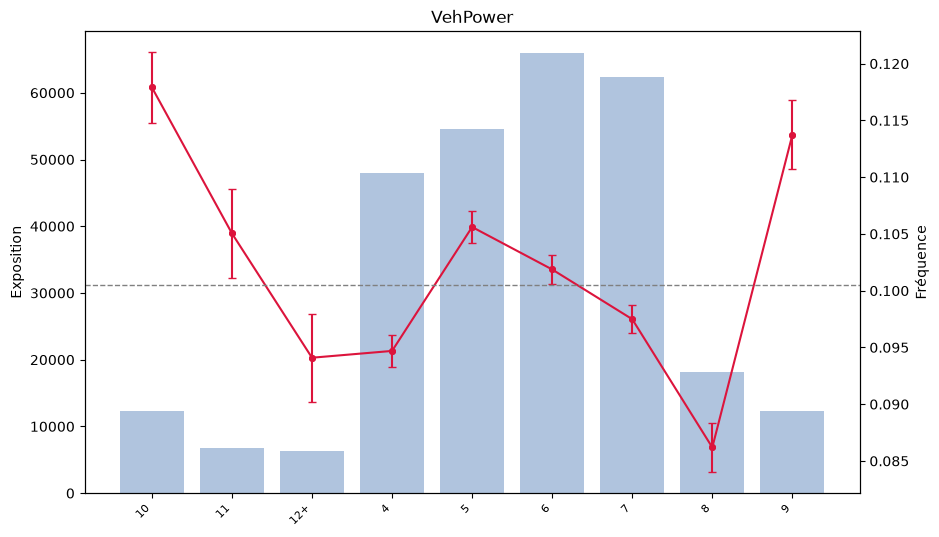

In [26]:
plot_freq_par_groupe(train_prep, "VehPower", errorbar=True)

Après avoir revu les fréquences par groupe, au vu des intervalles de confiance, le saut de 41% entre 8 et 9 n'est sûrement pas un artefact. En réalité on ne sait pas comment cette variable est construite, s'il s'agit de groupe de puissance en chevaux, ou si cela traduit des catégorie de véhicules différents (voiture, utilitaires ...).

Nous allons donc essayer de regrouper des catégorie qui présentent des fréquences quasi similaires.

In [27]:
GROUPES_POWER = {"4": "4", "5": "5-6", "6": "5-6", "7": "7", "8": "8", "9": "9-10", "10": "9-10", "11": "11", "12+": "12+"}

train_prep["vehpower_grp_2"] = train_prep["VehPower"].astype(str).replace(GROUPES_POWER)
test_prep["vehpower_grp_2"] = test_prep["VehPower"].astype(str).replace(GROUPES_POWER)

vehpower2_freq_formula = ("ClaimNb ~ C(age_grp2, Treatment('30-39')) + C(bm_grp, Treatment('50'))"
        " + C(dens_grp, Treatment('medium')) + C(vehage_grp, Treatment('5-10'))"
        " + C(VehGas, Treatment('Regular')) + C(vehpower_grp_2, Treatment('5-6'))"
        " + C(VehBrand, Treatment('B12')) + C(Region, Treatment('R24'))" 
         " + age40p:dense")

glm_vehpower2 = smf.glm(vehpower2_freq_formula, data=train_prep,family=sm.families.Poisson(),offset=offset_train).fit()

comparer_modeles_glm(glm_reference, glm_vehpower2, alpha=0.05)


=== COMPARAISON DE MODÈLES GLM (n = 542410, |Δddl| = 2) ===
Action détectée : RETRAIT OU FUSION
Statistique LR calculée : 3.87 (p-value : 1.4466e-01)
-----------------------------------------------------------------
1. Test LR (α=5.0%)   : Seuil = 5.99 ➔ OK Non-rejet de H0 : La simplification est acceptable.
2. Critère AIC        : Seuil = 4.00 ➔ OK Changement validé pour l'AIC.
3. Critère BIC        : Seuil = 26.41 ➔ OK Changement validé pour le BIC.


{'lr_stat': 3.8667756570794154,
 'p_value': 0.1446572932951431,
 'ddl': np.int64(2),
 'action': 'RETRAIT OU FUSION',
 'valide_test': True,
 'valide_aic': True,
 'valide_bic': True}

Les fusions de 5 et 6 et de 9 et 10 sont retenues. Nous allons tester avec une fusion supplémentaire sur 11 et 12+.

In [28]:
GROUPES_POWER = {"4": "4", "5": "5-6", "6": "5-6", "7": "7", "8": "8", "9": "9-10", "10": "9-10", "11": "11+", "12+": "11+"}

train_prep["vehpower_grp_3"] = train_prep["VehPower"].astype(str).replace(GROUPES_POWER)
test_prep["vehpower_grp_3"] = test_prep["VehPower"].astype(str).replace(GROUPES_POWER)

vehpower3_freq_formula = ("ClaimNb ~ C(age_grp2, Treatment('30-39')) + C(bm_grp, Treatment('50'))"
        " + C(dens_grp, Treatment('medium')) + C(vehage_grp, Treatment('5-10'))"
        " + C(VehGas, Treatment('Regular')) + C(vehpower_grp_3, Treatment('5-6'))"
        " + C(VehBrand, Treatment('B12')) + C(Region, Treatment('R24'))" 
         " + age40p:dense")

glm_vehpower3 = smf.glm(vehpower3_freq_formula, data=train_prep,family=sm.families.Poisson(),offset=offset_train).fit()

comparer_modeles_glm(glm_reference, glm_vehpower3, alpha=0.05)


=== COMPARAISON DE MODÈLES GLM (n = 542410, |Δddl| = 3) ===
Action détectée : RETRAIT OU FUSION
Statistique LR calculée : 11.97 (p-value : 7.4774e-03)
-----------------------------------------------------------------
1. Test LR (α=5.0%)   : Seuil = 7.81 ➔ KO Rejet de H0 : La simplification dégrade trop le modèle.
2. Critère AIC        : Seuil = 6.00 ➔ KO Changement rejeté pour l'AIC.
3. Critère BIC        : Seuil = 39.61 ➔ OK Changement validé pour le BIC.


{'lr_stat': 11.972651378397131,
 'p_value': 0.007477434907765964,
 'ddl': np.int64(3),
 'action': 'RETRAIT OU FUSION',
 'valide_test': False,
 'valide_aic': False,
 'valide_bic': True}

Deux regroupements ont été testés. La version à six modalités (fusion supplémentaire de 11 et 12+) coûte LR = 11,97 pour 3 paramètres : rejetée par le test et l'AIC, acceptée par le seul BIC.

La version à sept modalités — 4 / 5-6 / 7 / 8 / 9-10 / 11 / 12+ — coûte LR = 3,87 pour 2 paramètres et passe les trois critères (seuils 5,99 / 4 / 26,4). Elle est retenue.

L'écart entre les deux versions montre que la fusion 11 + 12+ coûte à elle seule 8,1, soit plus du double des deux autres réunies. Les deux modalités affichaient pourtant le même rapport de 2,0 σ que 5/6 en analyse marginale, mais sur des expositions cinq fois plus faibles. Une fois les autres variables contrôlées, le modèle les distingue mieux que ne le laissait prévoir la comparaison brute.

#### Déviance de Poisson hors échantillon

In [29]:
formule_final_freq = ("ClaimNb ~ C(age_grp2, Treatment('30-39')) + C(bm_grp, Treatment('50'))"
        " + C(dens_grp, Treatment('medium')) + C(vehage_grp, Treatment('5-10'))"
        " + C(VehGas, Treatment('Regular')) + C(vehpower_grp_2, Treatment('5-6'))"
        " + C(VehBrand, Treatment('B12')) + C(Region, Treatment('R24'))" 
         " + age40p:dense")

glm_poisson_final = smf.glm(formule_final_freq, data=train_prep,family=sm.families.Poisson(),offset=offset_train).fit()

start = np.append(glm_poisson_final.params.to_numpy(), np.log(1.5))

glm_nb_final = smf.negativebinomial(formule_final_freq, data=train_prep, offset=offset_train,loglike_method="nb2").fit(start_params=start , maxiter=200, disp=1)

print(glm_nb_final.summary())

Optimization terminated successfully.
         Current function value: 0.207285
         Iterations: 69
         Function evaluations: 72
         Gradient evaluations: 72
                     NegativeBinomial Regression Results                      
Dep. Variable:                ClaimNb   No. Observations:               542410
Model:               NegativeBinomial   Df Residuals:                   542359
Method:                           MLE   Df Model:                           50
Date:                Mon, 02 Nov 2026   Pseudo R-squ.:                 0.03838
Time:                        09:32:45   Log-Likelihood:            -1.1243e+05
converged:                       True   LL-Null:                   -1.1692e+05
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                                    coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------

On recalcule le facteur de recalage pour la negative binomial.

In [30]:
mu_final = glm_nb_final.predict(train_prep, offset=offset_train)
print(f"écart : {100*(mu_final.sum() - y_train.sum())/y_train.sum():.2f} %")
facteur_recalage = y_train.sum() / mu_final.sum()

écart : 1.28 %


In [31]:
offset_test = np.log(test_prep["Exposure"])
y_test = test_prep["ClaimNb"]

def deviance_test(modele, recalage=1.0):
    mu = modele.predict(test_prep, offset=offset_test) * recalage
    return mean_poisson_deviance(y_test, mu)


resultats = {}
for nom, m, rec in [
    ("base (sans interaction)", m_base, 1.0),
    ("final Poisson", glm_poisson_final, 1.0),
    ("final NegBin", glm_nb_final, facteur_recalage),
    ("final NegBin sans recalage", glm_nb_final, 1.0)]:
    resultats[nom] = deviance_test(m, rec)

print(pd.Series(resultats).sort_values().round(5))



final Poisson                 0.31314
final NegBin                  0.31319
final NegBin sans recalage    0.31320
base (sans interaction)       0.31323
dtype: float64


Le modèle final bat le modèle de base sur les données de test, ce qui montre que le modèle et les ajustements faits se généralisent bien.


Réserve sur les écarts :  l'écart entre le meilleur et le pire : 0,00009, soit 0,03 %. Le test contient 7225 sinistres, donc une incertitude relative de 1,2% soit 40 fois l'écart observé. Aucun de ces classements n'est donc statistiquement significatif.

On note que la Poisson devance la binomiale négative hors échantillon alors que cette dernière domine nettement sur l'AIC et le BIC. Ces critères mesurent l'ajustement sur les données d'apprentissage ; la déviance de test mesure la prédiction. L'avantage de la Poisson tient à sa calibration exacte, propriété du lien canonique, tandis que la meilleure modélisation de la variance par la binomiale négative n'apporte rien à une métrique qui n'évalue que la moyenne prédite.

La déviance moyenne est un critère peu discriminant pour un tarif : deux modèles peuvent l'égaler tout en ordonnant différemment les risques. C'est cet ordonnancement qu'évaluent le Gini et le lift chart. 

#### Test du Lift-Chart

On veut évaluer la capacité prédictive et discriminatoire du modèle.

But : Classer toutes les polices de la moins risquée à la plus risquée en utilisant le modèle, puis les séparer en 10 groupe d'exposition egale, et comparer la prédiction de fréquence annualisée avec la fréquence annulisée empirique calculée sur les données.

        observe  predit_poisson  predit_nb  ecart_poisson_%  ecart_nb_%
groupe                                                                 
0        0.0455          0.0472     0.0465           3.7216      2.1641
1        0.0560          0.0596     0.0588           6.3195      4.9481
2        0.0703          0.0665     0.0658          -5.3044     -6.4066
3        0.0782          0.0722     0.0715          -7.6635     -8.6512
4        0.0794          0.0777     0.0769          -2.0934     -3.0617
5        0.0841          0.0835     0.0827          -0.7283     -1.6528
6        0.0859          0.0912     0.0904           6.1066      5.2120
7        0.1092          0.1057     0.1049          -3.2643     -3.9583
8        0.1429          0.1378     0.1373          -3.5928     -3.9325
9        0.2577          0.2663     0.2730           3.3188      5.9411


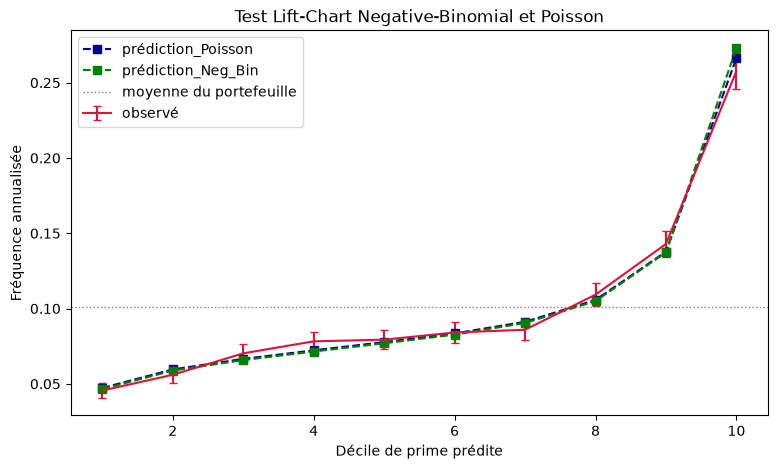

In [32]:
t_poisson = lift_table(glm_poisson_final, test_prep)
t_nb= lift_table(glm_nb_final, test_prep, recalage=facteur_recalage)

fig, ax = plt.subplots(figsize=(9, 5))
x = range(1, len(t_poisson) + 1)
ax.errorbar(x, t_poisson["observe"], yerr=1.96 * t_poisson["sigma"], color="crimson", capsize=3, label="observé")
ax.plot(x, t_poisson["predit"], "s--",color="darkblue", label="prédiction_Poisson")
ax.plot(x, t_nb["predit"], "s--",color="green", label="prédiction_Neg_Bin")
ax.axhline(t_poisson["sinistres"].sum() / t_poisson["exposition"].sum(), ls=":", color="gray", lw=1, label="moyenne du portefeuille")
ax.set_xlabel("Décile de prime prédite")
ax.set_ylabel("Fréquence annualisée")
ax.set_title("Test Lift-Chart Negative-Binomial et Poisson")
ax.legend()

comp = pd.DataFrame({
    "observe": t_poisson["observe"], # mêmes observations peu importe le modèle
    "predit_poisson": t_poisson["predit"],
    "predit_nb": t_nb["predit"],
})
comp["ecart_poisson_%"] = 100 * (comp["predit_poisson"] / comp["observe"] - 1)
comp["ecart_nb_%"] = 100 * (comp["predit_nb"] / comp["observe"] - 1)
print(comp.round(4))


##### Dicrimination Le dernier décile affiche une fréquence observée de 0,258 contre 0,046 pour le premier, soit un rapport de 5,6. La courbe observée est strictement monotone sur les dix déciles : l'évolution des risques est correct sur toute la distribution.

La forme du profile est celle attendue d'un tarif, le risque n'est pas lissé artificiellement mais isolé sur une partie de profils très dégradés.


##### Calibration Écart absolu moyen : 4,19 % pour la Poisson, 4,59 % pour la binomiale négative recalée. 

La surestimation des bons profils est confirmée mais atténuée. Les déciles 1 et 2 sont surestimés de 3,7 % et 6,3 %, dans le même sens que l'écart de 11,8 % relevé plus haut sur le sous-groupe {30-39 ans, bonus 50, véhicule 5-10 ans}. L'amplitude mesurée ici, sur un ensemble bien plus large, suggère que la valeur ponctuelle était amplifiée par le bruit local.

##### Choix du modèle de tarif 

La Poisson est mieux calibrée sur 7 déciles sur 10, et son avantage se concentre sur le dernier décile (+3,3 % contre +5,9 %), celui qui porte le quart des sinistres et sur lequel une erreur de tarification a l'effet commercial le plus direct.

Le recalage uniforme appliqué à la binomiale négative corrige le niveau global mais pas la structure des écarts. La Poisson, dont le lien canonique impose l'égalité des totaux sur chaque colonne de la matrice de design, conserve une meilleure calibration locale.

|Critère|Poisson|Binomiale Négative|
|---|---|---|
|AIC / BIC||✓|
|Déviance hors échantillon|✓||
|Calibration global|✓ (exacte)|1,28 % à recaler|
|Estimation sur la dispertion||✓ (α = 2,19)|

La Poisson est retenue comme modèle de tarif. Elle l'emporte sur les trois critères hors échantillon, qui mesurent ce qu'un assureur constaterait réellement, alors que l'AIC et le BIC n'évaluent que l'ajustement aux données d'apprentissage.

La binomiale négative est conservée pour son paramètre de dispersion, nécessaire au calcul du chargement de sécurité en phase 6 — la Poisson y imposerait Var = E et conduirait à sous-estimer le capital requis.

#### Test GINI

Le test Gini permet de mesurer la capacité de discrimination du modèle.

Le but est de classer les polices des moins risquées aux plus risquées selon le modèle, de tracer la part cumulée des sinistres en fonction de la part cumulée d'exposition et de mesurer l'écart entre la courbe obtenue et la diagonale (digonale = 0 différence entre les plus risqués et les moins risqué = 0 discrimination). Le Gini est le double de cet aire.

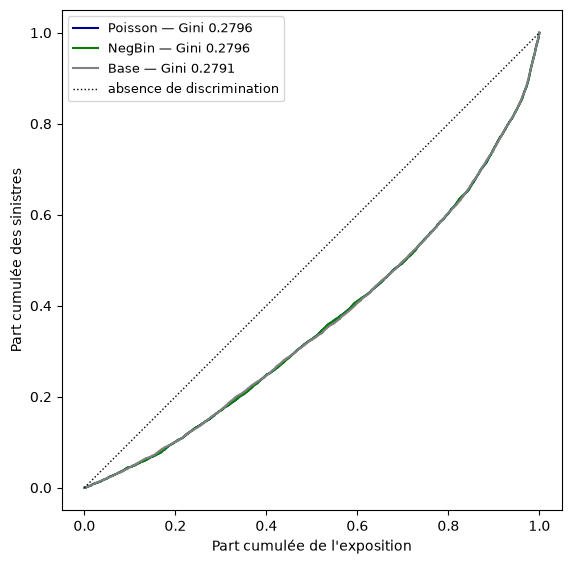

In [33]:



fig, ax = plt.subplots(figsize=(6.5, 6.5))

for nom, m, rec, couleur in [
    ("Poisson", glm_poisson_final, 1.0, "darkblue"),
    ("NegBin", glm_nb_final, facteur_recalage, "green"),
    ("Base", m_base, 1.0, "gray")]:

    x, y, g = gini(m, test_prep, rec)
    ax.plot(x, y, color=couleur, label=f"{nom} — Gini {g:.4f}")

ax.plot([0, 1], [0, 1], "k:", lw=1, label="absence de discrimination") # on plot la diagonale
ax.set_xlabel("Part cumulée de l'exposition")
ax.set_ylabel("Part cumulée des sinistres")
ax.set_aspect("equal")
ax.legend(loc="upper left", fontsize=9)

Le modèle de base n'est qu'à 0.0005 de Gini d'écart avec le modèle final, les interaction et les fusions n'apportent qu'un gain de discrimination de 0.2%.

La discrimination semble bonne, 40% des usagers les plus prudents ne représentent qu'environ 20% des sinistres, et les 20% les plus risqués représentent 40% des sinistres. Le modèle est donc capable de discriminer les profils à risque élevé de ceux à risque faible.

#### Enregistrement des coefficients du modèle final

In [35]:
coefs = pd.DataFrame({
    "coef": glm_poisson_final.params,
    "facteur": np.exp(glm_poisson_final.params),
    "std_err": glm_poisson_final.bse,
    "z": glm_poisson_final.tvalues,
})
coefs.to_csv("../outputs/grille_frequence.csv")

meta = {
    "formule": FORMULE_FREQUENCE,
    "famille": "Poisson",
    "offset": "log(Exposure)",
    "random_state_split": 42,
    "alpha_negbin": float(np.exp(glm_nb_final.params["alpha"])),
    "facteur_recalage_negbin": float(facteur_recalage),
    "gini_test": 0.2796,
    "deviance_test": 0.31314,
}
with open("../outputs/modele_frequence.json", "w") as f:
    json.dump(meta, f, indent=2, ensure_ascii=False)

